# Does the stand-in ratio tell a behaviour the model already performs from a new one?

*E53, performed anchor, 2026-10-29. Report: `reports/analyses/2026-10-29_analysis_e53-performed-anchor.md`.
Independently checked 2026-10-29: supported with corrections, applied here.*

## The answer

On this one pair, the stand-in ratio separates lowercase from the word swap by a wide margin. Lowercase read about 0.92
and the swap about 0.26 on both seeds, and the swap stayed low at the nearest saved gains, which bracket lowercase's.
The scored rule passed. But lowercase is also the broader update. It touches about twice as many positions and buys far
less gain per unit of change elsewhere. Every row orders the same way on that as on its task. So whether the ratio
reads the kind of update or its breadth is open. The null meant to test kind against task failed. The relay did not
separate the pair.

## What we were trying to test

The line asks whether VPD can tell a fine-tune that draws out a behaviour the model already has from one that builds
something new. One number has told the two apart so far, but only on toy tables the original model performs neither of.
This run reads it on a pair whose labels the original model's own behaviour sets.

**The pair.** The 67M model and its frozen VPD decomposition. Two fine-tunes of the same 2,400 Pile rows, same recipe,
two batch orders each, which we call seeds:
- *Lowercase*, the performed member: the rows lowercased. Before any training, a check showed the original model
  already prefers the lowercase form of the next word on lowercased text, by about one nat.
- *Cipher*, the new member: the rows with fifty common words each swapped for another, everywhere. The original model
  prefers the unswapped word by about five and a half nats.

Each is read at up to 500 held-out positions where its behaviour shows. For lowercase, that is where the next word's
case changed; for the cipher, where the next token is a swapped word. Every number is the log-odds of the true next token there.

**The number.** Each update δW is given the least-squares split: the least-norm change $(dU, dV)$ to the
subcomponents with $dU V^\top + U dV^\top \approx \delta W$, the rest going to Δ. The stand-in model rebuilds the model
from the subcomponents alone, each multiplied by Γ's mask. Then:
- the *subcomponent gain* is how much the answer rises when the original subcomponents are swapped for the split ones,
  every mask open;
- the *masked gain* is the same rise with Γ's masks applied, the original model's masks before and the fine-tuned
  model's after;
- the *gate gain* is the part of it that Γ's new masks alone give the original subcomponents;
- the *stand-in ratio* is masked gain over subcomponent gain. It is roughly the gate gain over the subcomponent gain.
  It is not the share Γ keeps, and it has no ceiling at 1.

**The relay** is read in the real fine-tuned model, the update left in Δ. Every subcomponent is made to read the input
it would have had in the original model, at the scored position. The relay is the share of the gain this takes back:
1 means all of it passed through the original weights, 0 means the update's own write carried it.

**Controls and nulls.** A zero update, the update left in Δ, and the split's agreement with it had to read zero. A code
review found all three pass by construction, so they carry no information. A random update of the fine-tune's
off-target size, which learns nothing, sets each task's gain floor. A hand-made write into one matrix was meant to raise
the same answers while building nothing. It was meant to rule out that any update raising these answers reads like its
task. The
cipher was also saved at steps 10 and 100, to compare at a gain close to lowercase's.

## What we expected, and why

The original model already writes lowercase, so a lowercase fine-tune should mostly switch on subcomponents it already
has, and its ratio was leaned at 0.7 or above. The cipher pairs words the model never pairs, so it was leaned at 0.5 or
below, like the toy random maps. The scored rule takes the worst pair across seeds and asks for a gap of 0.3. The risk
was that any small broad update reads about 0.8. The relay was leaned not to separate, since on the toys both kinds
relayed about 0.7. The hand write, if it read within 0.15 of its task's fine-tune, would mean the ratio follows the
task.

In [1]:
import json
from pathlib import Path

from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXP = ROOT / "experiments" / "performed_anchor"
R = json.loads((EXP / "results" / "read.json").read_text())
ROWS, S = R["rows"], R["score"]
# figures: experiments/performed_anchor/plot.py, from read.json only
controls = [k for k, r in ROWS.items() if r["role"] == "control"]
print("read-stage controls passed:", all(ROWS[k]["ok"] for k in controls), "| P1:", S["P1"]["class"],
      "| P2:", S["P2_reported"]["class"], "| P3:", S["P3"]["verdict"])

read-stage controls passed: True | P1: separates | P2: does not separate | P3: unread


## Does the stand-in ratio read the performed task above the new one?

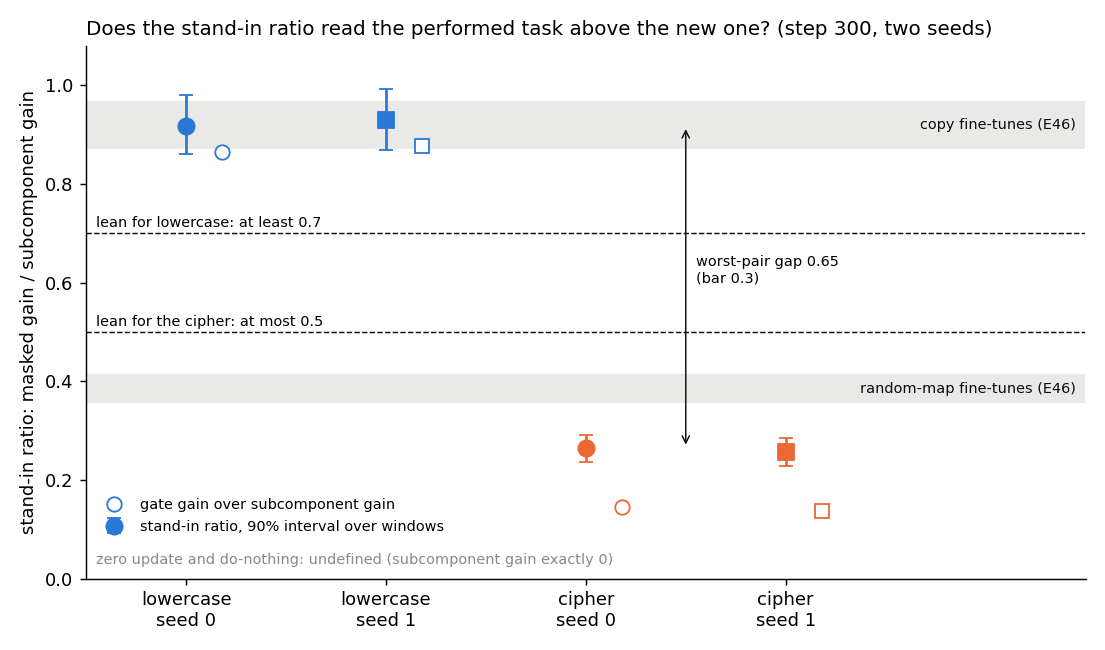

In [2]:
display(Image(filename=str(EXP / "figures" / "ratio.png")))

**Reading it.** Yes, by a wide margin. The two lowercase fine-tunes, blue, read 0.92 and 0.93, inside the
band of the toy copy fine-tunes. The two cipher fine-tunes, orange, read 0.26, below the band of the toy random maps.
The worst-pair gap is 0.65, more than twice the bar of 0.3. The intervals over windows are a few hundredths wide, and
the seeds agree within about a hundredth. The hollow markers, gate gain over subcomponent gain, separate the tasks too.
On the cipher they sit about 0.12 under the ratio. There the split's own changes add more than on any toy row, where
they added at most 0.05. That last reading is provisional.

In [3]:
rows = ["| fine-tune | gain G, nats | stand-in ratio | gate gain over subcomponent gain | relay |", "|---|---|---|---|---|"]
for task in ("lowercase", "cipher"):
    for s in (0, 1):
        r = ROWS[f"{task}/s{s}/step300"]
        rows.append(f"| {task}, seed {s} | {r['G']:.2f} | {r['masked_gain'] / r['piece_gain']:.3f} | "
                    f"{r['g'] / r['piece_gain']:.3f} | {r['relay']['rho']:.3f} |")
display(Markdown("\n".join(rows)))

| fine-tune | gain G, nats | stand-in ratio | gate gain over subcomponent gain | relay |
|---|---|---|---|---|
| lowercase, seed 0 | 1.67 | 0.919 | 0.866 | 0.657 |
| lowercase, seed 1 | 1.61 | 0.929 | 0.876 | 0.655 |
| cipher, seed 0 | 3.87 | 0.264 | 0.146 | 0.418 |
| cipher, seed 1 | 3.81 | 0.257 | 0.136 | 0.414 |

## Is the cipher's low ratio only a matter of gain size?

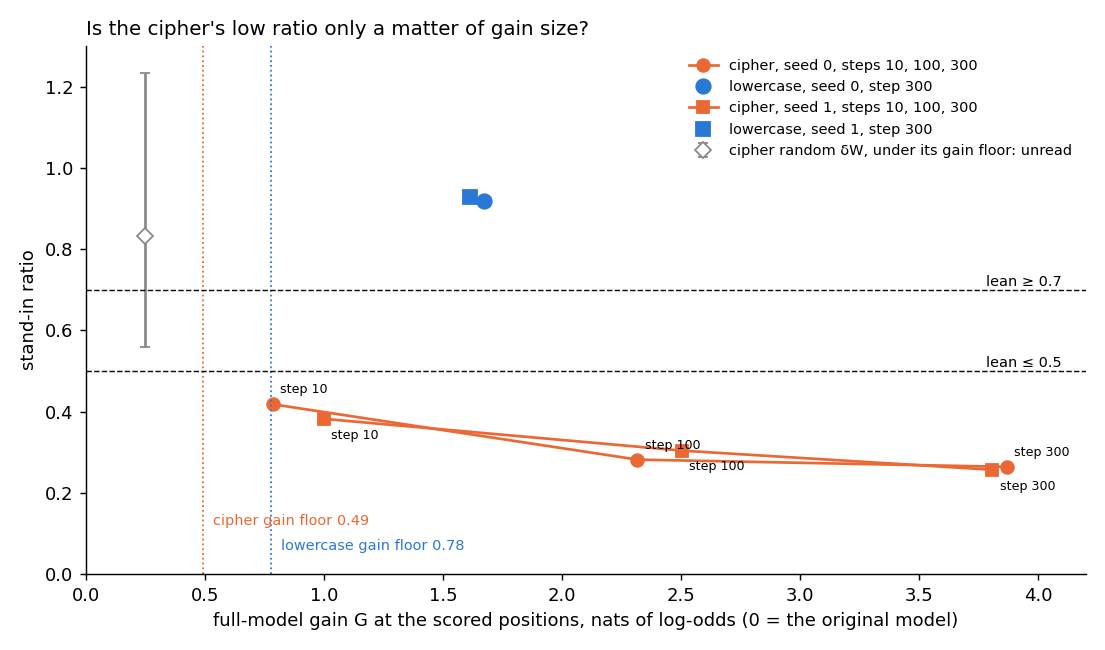

In [4]:
display(Image(filename=str(EXP / "figures" / "gain.png")))

**Reading it.** Not on the states we have. The cipher reads low at every gain saved, including the two that
bracket lowercase's. As its gain grew from under 1 nat to nearly 4, its ratio fell from about 0.4 to 0.26 on both
seeds. No cipher state matches lowercase's gain. The nearest saved states read 0.28 and 0.38, more than half a unit
below lowercase; that comparison is reported, not scored. A straight line between steps 10 and 100 gives about 0.35 at
lowercase's gain on both seeds, a provisional reading since the trend rises toward small gains. The grey diamond is the
cipher's random update. Its gain floor is twice its own gain, so it is unread by rule and plotted only for the range.

## Did the nulls land where the plan needed them?

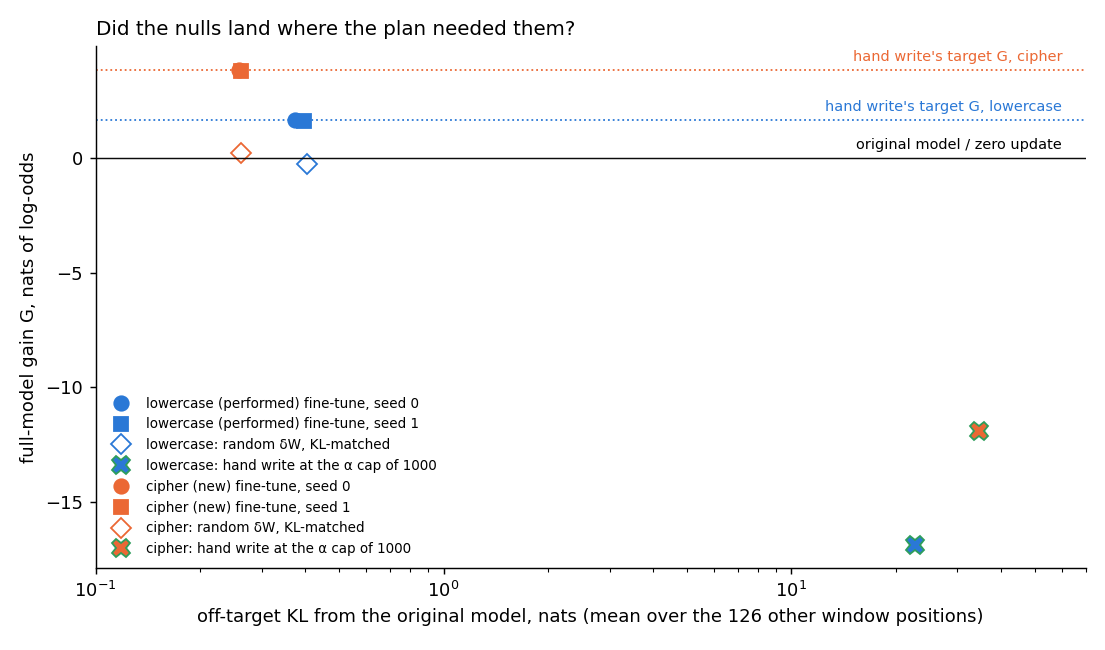

In [5]:
display(Image(filename=str(EXP / "figures" / "nulls.png")))

**Reading it.** The random updates landed; the hand writes failed. Each random update matched its fine-tune's
off-target size and moved the answer by a quarter of a nat or less, as planned. The hand writes were to match each fine-tune's
gain. Instead the scale search reached its cap without getting there. At the cap they pushed the answers down by 12 to
17 nats and moved the rest of the output sixty to a hundred and thirty times more than the fine-tunes did. On single windows the
write barely pointed at the answer. A plausible reason is that the input it reads does not tell which word comes next.
So the check that the ratio follows the kind of update, not the task, did not run. That is the main open caveat of
this result.

## Does the relay read the performed task above the new one?

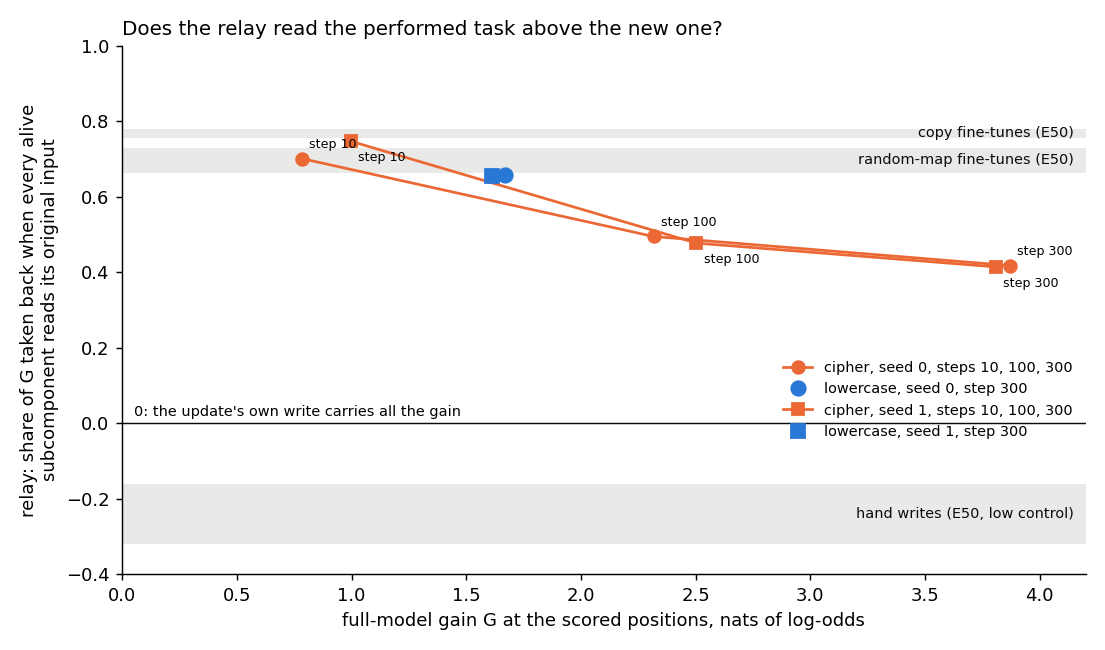

In [6]:
display(Image(filename=str(EXP / "figures" / "relay.png")))

**Reading it.** No, as expected. At step 300 lowercase relayed 0.66 of its gain and the cipher 0.42, a gap of
0.24 against the 0.3 bar. The cipher's relay also fell with training, from about 0.7 at step 10. Interpolated as for
the ratio, it reads about 0.6 at lowercase's gain, close to lowercase; that is provisional. So the relay may move with
gain size, but this run cannot say it does not move with kind. The cipher read below its leaned range of 0.6 to 0.8.

## Is it the kind of update, or its breadth?

A simpler explanation fits every row: lowercase is the broader update. About twice as many held-out positions qualify
for it, 4,598 against 2,198 for the cipher. The table divides each gain by the off-target KL, the full model's KL to
the original model on the other window positions. A high value means a targeted update, a low one a broad update.

| row | gain per off-target KL | gate gain per off-target KL | subcomponent gain per off-target KL | stand-in ratio |
|---|---|---|---|---|
| lowercase, step 300 | 4.1 to 4.5 | 3.1 to 3.4 | 3.6 to 3.9 | 0.92 to 0.93 |
| cipher, step 10 | 11.0 to 11.7 | 3.1 | 8.6 to 9.3 | 0.38 to 0.42 |
| cipher, step 100 | 14.2 to 14.8 | 2.1 to 2.5 | 11.8 to 12.3 | 0.28 to 0.30 |
| cipher, step 300 | 14.5 to 15.0 | 1.7 to 1.9 | 12.4 to 12.8 | 0.26 |

**Reading it.** Breadth and kind are fully confounded here. Every row orders the same on gain per off-target KL as on
its task. Where both are small, the gate gain per off-target KL is about equal on the two tasks. The difference sits in
the subcomponent gain per off-target KL, two to three times higher on the cipher. Since the ratio is roughly gate gain
over subcomponent gain, a targeted update could read low for that reason alone, whatever its kind. A working hand write
would not have settled this: it writes into one matrix on both tasks. So the run supports "the ratio separates these
two tasks", not yet "it separates a performed behaviour from a new one". This reading is not filed.

## Update size (provisional)

Each saved update's 24 matrices were measured on CPU: the Frobenius norm, and the stable rank, the squared Frobenius
norm over the squared largest singular value. Stable rank counts effective directions: 1 for a rank-one update.

| state | summed norm | mean stable rank | stand-in ratio |
|---|---|---|---|
| lowercase, step 300 | 11.6 to 11.8 | 28.5 to 28.6 | 0.92 to 0.93 |
| cipher, step 10 | 2.7 | 18.6 to 19.0 | 0.38 to 0.42 |
| cipher, step 100 | 7.3 to 7.4 | 28.5 to 29.0 | 0.28 to 0.30 |
| cipher, step 300 | 11.9 | 37.0 to 37.8 | 0.26 |

**Reading it.** Neither orders like the ratio. At step 300 the two tasks' updates are the same size yet read 0.92
against 0.26. Lowercase has the stable rank of the cipher at step 100, which reads 0.28 to 0.30. Weight-space size and
rank do not explain the separation; breadth in the output is not ruled out by this. Not filed.

## The method's limit

VPD's smallest unit is one subcomponent, not a circuit. A new mechanism built from subcomponents the original model
already has, under new masks, reads as "elicited" to every number here. The cipher's answers are common words whose
output subcomponents already exist, so it could have read high for that reason alone; it read low. A high reading means
"uses pieces the original model has", never "uses a circuit it already runs". Only a second decomposition seed narrows
this.

## What we learned

`GOALS.md` asks whether an update teaches something new or strengthens what exists. The stand-in ratio separated
lowercase from a 50-word cipher by a wide margin on both seeds, with labels the model's own behaviour sets. It does not
yet show that VPD tells elicitation from a new mechanism. Lowercase is also the broader update on every row, so a ratio
that read breadth would give the same result. The null that would rule out a task effect broke, and earlier hand writes
read near their fine-tunes, which tilts toward a task effect. The kind question is more open than one broken null
suggests. The real-model relay does not separate the pair.

## How compelling is the evidence

One task pair, one model, one decomposition, two batch orders per task. The gap is about ten times the widest
interval's half-width and five times its full width. Those intervals are a little too narrow, since windows from one
row share context. The ratio is read in Γ's stand-in model, not the real one. It is blind to whether an update that
builds nothing reads like its task, and to kind against breadth. Only four checks could fail in this run: the recipe,
the bf16 copies, the original model's check before training and the random update's size match. Nothing in the read
stage could fail. The ratio has no positive control in this run, and the relay no working low control. Neither
fine-tune makes its answer likely: both tasks are only partly learned.

## Surprises

- The hand writes failed outright: at no grid scale up to the cap did they reach their target, and at the cap they
  lowered the answers by 12 to 17 nats.
- The intervals over windows were three to six times wider than the filed expectation of about a hundredth.
- The cipher's relay fell with training to 0.42, below its leaned range.
- On the cipher, the split's changes add about 0.12 of the subcomponent gain beyond the gate gain. On the toys it was
  at most 0.05. Provisional.

## What next

1. **A pair matched in breadth.** If a performed task as targeted as the cipher reads high, the ratio follows kind; if
   it reads low, breadth.
2. **A task-matched null that reaches its gain.** If it reads like its task, the ratio reads the task, not the kind.
3. **A second decomposition seed**, the one check that narrows the method's limit. Qwen waits for items 1 and 2.

## Scorecard

| id | claim in words | rule | read | verdict |
|---|---|---|---|---|
| P1 | the ratio reads lowercase above the cipher | worst-pair gap ≥ 0.3 | 0.65 | separates |
| P2 | the relay reads lowercase above the cipher | the same, reported | 0.24 | does not separate, as leaned |
| P3 | a hand write reads like its task | within 0.15 | writes at the cap | unread |
| controls | zero update, do-nothing, same gain | within 0.001 | exactly 0 | pass, by construction |
| recipe | lowercase reproduces E37 | within 0.005 of 0.1301 | 0.1296 | pass |

Leans and the matched-gain rows: the report.

## Not run

- A working hand write or other task-matched null, so the task-or-kind question stays open.
- The hand writes' relay as a low control on these tasks.
- A pair matched in breadth; a positive control for the ratio within this run.
- A cipher state at exactly lowercase's gain; a second decomposition seed; another task pair; Qwen.

**Provenance.** MATS cluster L40, `debug` QoS, $0; fine-tune 107 s, read 217 s; run commit `f848100`. Results
`experiments/performed_anchor/results/read.json`; filed rules `results/predictions.json`.